# TuniShop — Data mining 03. Règles d'association (« acheté avec »)

**Auteure :** Sarra Abdeljaouad · **Phase :** data mining · **Source :** TuniShop_DWH (vues `bi`), via les tables de `05_Data/features` construites par `01_EDA/01_EDA_Global`

## Objectif

Trouver les articles **achetés ensemble** dans une même commande, pour proposer des **recommandations** (« les clients qui achètent X achètent aussi Y »).

Trois mesures décrivent une règle **X → Y** :

| Mesure | Définition | Exemple de lecture |
|---|---|---|
| **support** | part des paniers qui contiennent X **et** Y | 0,5 % des commandes contiennent les deux |
| **confiance** | parmi les paniers avec X, part qui contiennent aussi Y | 20 % des acheteurs de X prennent aussi Y |
| **lift** | confiance / part des paniers avec Y | 1 = hasard ; **1,5 = 50 % plus souvent que par hasard** ; < 1 = s'évitent |

**Méthode :** algorithme **FP-Growth** (bibliothèque `mlxtend`), règles apprises sur **2023-2024**, puis **vérifiées sur 2025** : une règle n'est « réutilisable » que si elle tient sur des paniers qu'elle n'a jamais vus.

**Produit pour la suite :** `06_Exports/Modeles/regles_association.parquet` et une fonction de recommandation (`features.recommander`) évaluée sur 2025.

**Plan :** 1. Données · 2. Les paniers · 3. Règles par niveau de détail · 4. Validation sur 2025 · 5. Affinités entre catégories · 6. Règles retenues et recommandation · 7. Évaluation de la recommandation · 8. Synthèse

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

# --- Paramètre : True = reconstruire la table depuis les vues du DWH avant l'analyse
#     (utile si le DWH a été rechargé depuis la dernière exécution de 01_EDA_Global)
RECONSTRUIRE = False

from mlxtend.frequent_patterns import association_rules, fpgrowth

## 1. Données

La table `commandes` (`05_Data/features/commandes.parquet`) a été construite par `01_EDA_Global` à partir des vues `bi` du DWH. Avec `RECONSTRUIRE = True`, on la reconstruit ici directement depuis le DWH. Dans les deux cas, une requête **🔗 SQL direct** vérifie ensuite que la table correspond toujours au DWH.

In [2]:
chargement.ouvrir_connexion()
if RECONSTRUIRE:
    vues, p = chargement.charger_donnees(source="dwh")
    features.sauvegarder(features.table_commandes(p), "commandes")
commandes = features.lire("commandes")
print(f"commandes : {len(commandes):,} lignes x {commandes.shape[1]} colonnes".replace(",", " "))

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)


commandes : 66 268 lignes x 33 colonnes


In [3]:
# 🔗 Contrôle SQL direct : commandes abouties par période, recalculées dans SQL Server
sql_ab = sql("""
    SELECT CASE WHEN d.annee <= 2024 THEN 'apprentissage' ELSE 'test' END AS periode,
           COUNT(*) AS commandes_abouties
    FROM bi.v_fact_commandes c
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
    JOIN bi.v_dim_date d            ON d.date_sk = c.date_commande_sk
    WHERE s.famille_statut = 'aboutie'
    GROUP BY CASE WHEN d.annee <= 2024 THEN 'apprentissage' ELSE 'test' END
""").set_index("periode")
sql_ab["table commandes"] = commandes[commandes["est_aboutie"] == 1]["periode"].value_counts()
sql_ab["statut"] = np.where(sql_ab["commandes_abouties"] == sql_ab["table commandes"], "OK", "ÉCART")

# Pour l'association, on écarte les rares paniers dont tous les produits sont inconnus (membre -1)
abouties = commandes[(commandes["est_aboutie"] == 1) & (commandes["nb_produits_distincts"] > 0)].copy()
sql_ab["paniers analysés"] = abouties["periode"].value_counts()
sql_ab

,commandes_abouties,table commandes,statut,paniers analysés
periode,,,,
test,26543,26543,OK,26538
apprentissage,32233,32233,OK,32230


## 2. Les paniers

Une règle d'association n'a de sens que pour les paniers de **plusieurs articles différents**. On regarde à trois niveaux de détail : catégorie (9), sous-catégorie (19) et produit (près de 600).

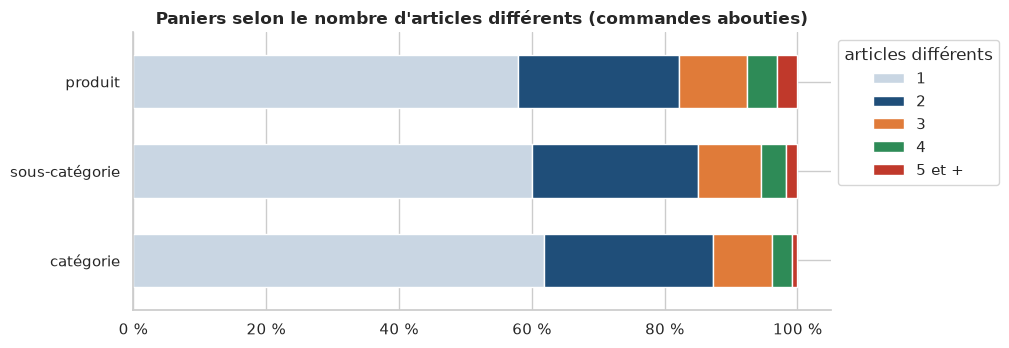

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.dm03_taille_paniers                           5 lignes


,1,2,3,4,5 et +
catégorie,0.619,0.254,0.090,0.030,0.008
sous-catégorie,0.600,0.250,0.096,0.037,0.017
produit,0.579,0.243,0.102,0.044,0.031


In [4]:
niveaux = {"catégorie": "categories", "sous-catégorie": "sous_categories", "produit": "produits"}
taille = pd.DataFrame({nom: abouties[col].apply(len).clip(upper=5).value_counts(normalize=True).sort_index()
                       for nom, col in niveaux.items()})
taille = taille.rename(index={5: "5 et +"})

fig, ax = plt.subplots(figsize=(9, 3.6))
taille.T.plot.barh(stacked=True, ax=ax, color=["#C9D6E3", cfg.BLEU, cfg.ORANGE, cfg.VERT, cfg.ROUGE], width=0.6)
ax.set_title("Paniers selon le nombre d'articles différents (commandes abouties)"); cfg.format_pourcent(ax, "x")
ax.legend(title="articles différents", bbox_to_anchor=(1, 1)); ax.set_ylabel("")
montrer("DM03_1_paniers")
cfg.exporter_table(taille, "DM03_taille_paniers")
taille.T

> **Lecture.** **62 % des commandes** ne contiennent qu'une seule catégorie (58 % un seul produit) : les règles d'association ne concernent que 38 à 42 % des paniers. C'est une limite importante pour la recommandation.

## 3. Règles par niveau de détail (apprentissage 2023-2024)

Seuils : support minimum de 0,3 % des paniers pour les catégories et sous-catégories (environ 100 commandes), 0,03 % pour les produits (une dizaine de commandes : le niveau produit est très clairsemé). On garde les règles de lift ≥ 1,1.

In [5]:
SEUILS = {"catégorie": 0.003, "sous-catégorie": 0.003, "produit": 0.0003}
LIFT_MIN = 1.1
app_cmd, test_cmd = abouties[abouties["periode"] == "apprentissage"], abouties[abouties["periode"] == "test"]

def regles(cmd, niveau, support_min, lift_min=0.0):
    """FP-Growth puis règles ; antécédents et conséquents en texte « A + B »."""
    m = features.matrice_paniers(cmd, niveaux[niveau])
    frequents = fpgrowth(m, min_support=support_min, use_colnames=True)
    if frequents.empty:
        return pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift"])
    r = association_rules(frequents, metric="lift", min_threshold=lift_min)
    for c in ["antecedents", "consequents"]:
        r[c] = r[c].apply(lambda s: " + ".join(sorted(s)))
    return r[["antecedents", "consequents", "support", "confidence", "lift"]]

toutes, bilan = {}, []
for niveau, s in SEUILS.items():
    r_app = regles(app_cmd, niveau, s, LIFT_MIN)
    r_tous = regles(app_cmd, niveau, s)                       # toutes les règles, pour voir la plage du lift
    toutes[niveau] = r_app
    bilan.append({"niveau": niveau, "règles (lift ≥ 1,1)": len(r_app),
                  "lift minimum observé": r_tous["lift"].min() if len(r_tous) else None,
                  "lift maximum observé": r_tous["lift"].max() if len(r_tous) else None})
bilan = pd.DataFrame(bilan).set_index("niveau")
bilan

,"règles (lift ≥ 1,1)",lift minimum observé,lift maximum observé
niveau,,,
catégorie,50,0.693,1.743
sous-catégorie,14,0.681,1.295
produit,196,0.509,3.644


> **Lecture.** Les règles sont **faibles** : au niveau catégorie, le lift maximum est de 1,74 (50 règles au-dessus de 1,1) ; au niveau sous-catégorie, de 1,30 seulement (14 règles). Au niveau produit, des lifts plus élevés apparaissent (jusqu'à 3,6), mais sur des supports minuscules (0,03 % des paniers, une dizaine de commandes) : ce sont probablement des coïncidences.

## 4. Validation sur 2025 : les règles tiennent-elles ?

Pour chaque règle apprise sur 2023-2024, on recalcule son support, sa confiance et son lift **sur les paniers de 2025**. Une règle est **stable** si son lift reste ≥ 1,1 en 2025.

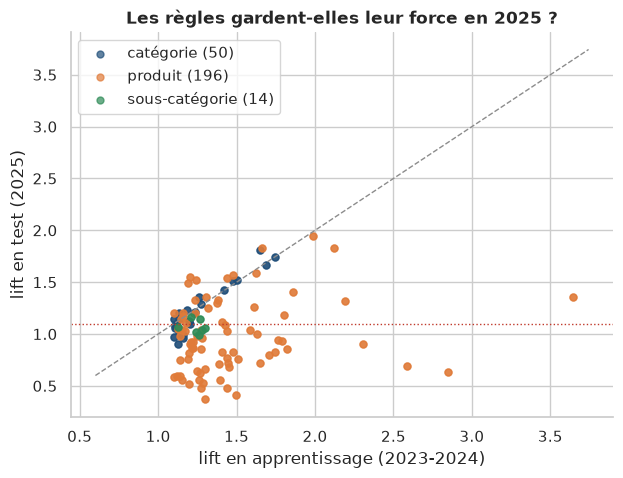

,regles,stables,lift_moyen_app,lift_moyen_2025
niveau,,,,
catégorie,50,30,1.262,1.234
produit,196,52,1.504,0.984
sous-catégorie,14,4,1.240,1.068


In [6]:
validees = []
for niveau, r_app in toutes.items():
    if r_app.empty:
        continue
    r_test = regles(test_cmd, niveau, SEUILS[niveau] / 3)     # seuil plus bas : on veut retrouver les règles, pas en créer
    r = r_app.merge(r_test, on=["antecedents", "consequents"], how="left", suffixes=("", "_2025"))
    r["niveau"] = niveau
    r["stable"] = r["lift_2025"].fillna(0) >= LIFT_MIN
    validees.append(r)
validees = pd.concat(validees, ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 5))
for i, (niveau, g) in enumerate(validees.groupby("niveau")):
    ax.scatter(g["lift"], g["lift_2025"], s=25, alpha=0.7, color=cfg.PALETTE[i], label=f"{niveau} ({len(g)})")
lim = [0.6, max(2.0, validees["lift"].max() + 0.1)]
ax.plot(lim, lim, color=cfg.GRIS, lw=1, ls="--"); ax.axhline(LIFT_MIN, color=cfg.ROUGE, lw=1, ls=":")
ax.set_xlabel("lift en apprentissage (2023-2024)"); ax.set_ylabel("lift en test (2025)")
ax.set_title("Les règles gardent-elles leur force en 2025 ?"); ax.legend()
montrer("DM03_2_stabilite_regles")
validees.groupby("niveau").agg(regles=("stable", "size"), stables=("stable", "sum"),
                               lift_moyen_app=("lift", "mean"), lift_moyen_2025=("lift_2025", "mean"))

> **Lecture.** La validation sur 2025 trie les règles : **30 règles sur 50** au niveau catégorie gardent leur force (lift moyen 1,26 en apprentissage, 1,23 en 2025), mais seulement **4 sur 14** au niveau sous-catégorie, et au niveau produit le lift moyen **retombe à 0,98** (le hasard) : les règles produit étaient bien du bruit. C'est exactement pourquoi on valide sur une période non vue.

## 5. Affinités entre catégories, paire par paire

Les règles fortes concernent des paniers de 3 ou 4 catégories. Pour comprendre si certaines catégories **s'attirent** vraiment, on regarde le lift de **chaque paire** de catégories.

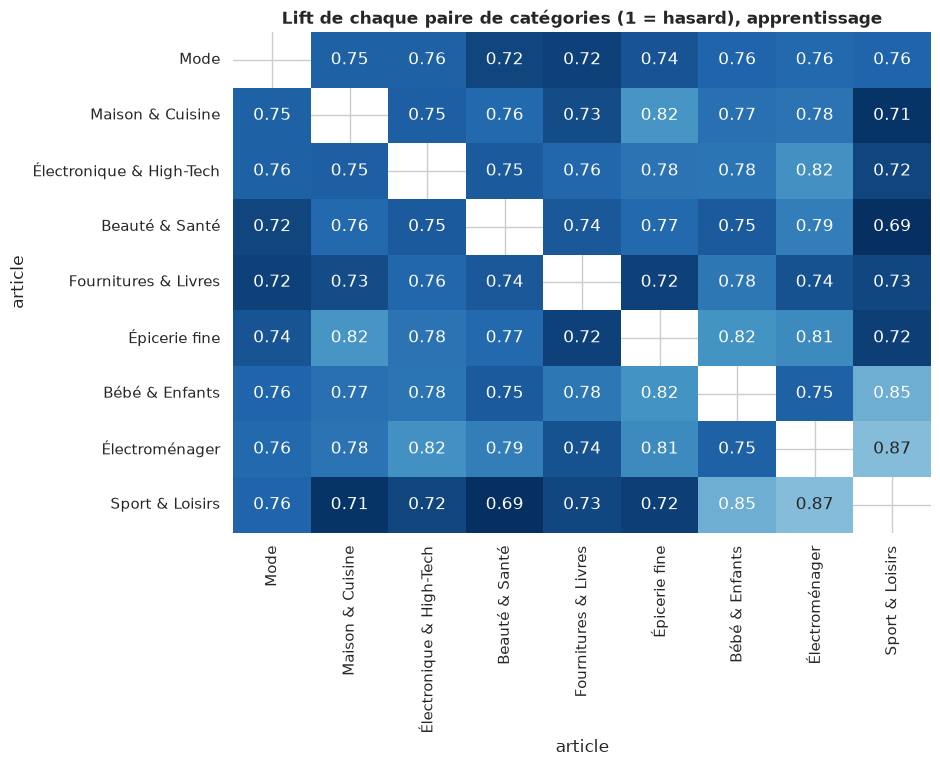

  ✔ ana.dm03_lift_paires_categories                   9 lignes


In [7]:
m = features.matrice_paniers(app_cmd, "categories")
m = m[m.sum(axis=1) >= 1]
p_cat = m.mean()
cats = p_cat.sort_values(ascending=False).index
lift_paires = pd.DataFrame(index=cats, columns=cats, dtype=float)
for a in cats:
    for b in cats:
        if a != b:
            lift_paires.loc[a, b] = (m[a] & m[b]).mean() / (p_cat[a] * p_cat[b])

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(lift_paires, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.7, vmax=1.3, cbar=False, ax=ax)
ax.set_title("Lift de chaque paire de catégories (1 = hasard), apprentissage")
montrer("DM03_3_lift_paires")
cfg.exporter_table(lift_paires, "DM03_lift_paires_categories")

> **Lecture.** Prises deux à deux, **toutes les paires de catégories ont un lift inférieur à 1** (0,69 à 0,87) : les paniers étant petits, ajouter une 2e catégorie est plus rare que le hasard ne le prévoit, et aucune catégorie n'en « attire » une autre. Les règles de lift > 1 trouvées plus haut concernent toutes des paniers de 3 ou 4 catégories : elles décrivent des **clients qui achètent beaucoup**, pas des produits complémentaires. Les données synthétiques n'ont pas de vraie structure « acheté avec ».

## 6. Règles retenues et recommandation

In [8]:
retenues = validees[validees["stable"]].sort_values(["niveau", "lift"], ascending=[True, False]).reset_index(drop=True)

# Popularité (part des paniers) en apprentissage : sert de complément quand aucune règle ne s'applique
populaires = {niveau: features.matrice_paniers(app_cmd, col).mean().sort_values(ascending=False).index.tolist()
              for niveau, col in niveaux.items()}

cfg.DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)
cfg.exporter_resultat(validees, cfg.DOSSIER_MODELES / "regles_association.parquet")
with open(cfg.DOSSIER_MODELES / "articles_populaires.json", "w", encoding="utf-8") as f:
    json.dump({k: v[:50] for k, v in populaires.items()}, f, ensure_ascii=False, indent=1)
cfg.exporter_table(retenues, "DM03_regles_retenues", index=False)
print(f"{len(validees)} règles enregistrées (dont {len(retenues)} stables) : 06_Exports/Modeles/regles_association.parquet")
retenues.head(10)

  ✔ ana.dm_regles_association                       260 lignes
  ✔ ana.dm03_regles_retenues                         86 lignes
260 règles enregistrées (dont 86 stables) : 06_Exports/Modeles/regles_association.parquet


,antecedents,consequents,support,confidence,lift,support_2025,confidence_2025,lift_2025,niveau,stable
0,Maison & Cuisine + Électronique & High-Tech,Beauté & Santé + Mode,0.004,0.086,1.743,0.003,0.079,1.743,catégorie,True
1,Beauté & Santé + Mode,Maison & Cuisine + Électronique & High-Tech,0.004,0.080,1.743,0.003,0.071,1.743,catégorie,True
2,Maison & Cuisine + Mode,Beauté & Santé + Électronique & High-Tech,0.004,0.058,1.686,0.003,0.054,1.665,catégorie,True
3,Beauté & Santé + Électronique & High-Tech,Maison & Cuisine + Mode,0.004,0.116,1.686,0.003,0.099,1.665,catégorie,True
4,Mode + Électronique & High-Tech,Beauté & Santé + Maison & Cuisine,0.004,0.066,1.647,0.003,0.062,1.810,catégorie,True
5,Beauté & Santé + Maison & Cuisine,Mode + Électronique & High-Tech,0.004,0.099,1.647,0.003,0.093,1.810,catégorie,True
6,Maison & Cuisine + Électronique & High-Tech,Fournitures & Livres + Mode,0.003,0.065,1.505,0.004,0.087,1.522,catégorie,True
7,Fournitures & Livres + Mode,Maison & Cuisine + Électronique & High-Tech,0.003,0.069,1.505,0.004,0.062,1.522,catégorie,True
8,Fournitures & Livres + Maison & Cuisine,Mode + Électronique & High-Tech,0.003,0.089,1.475,0.004,0.078,1.513,catégorie,True
9,Mode + Électronique & High-Tech,Fournitures & Livres + Maison & Cuisine,0.003,0.050,1.475,0.004,0.069,1.513,catégorie,True


In [9]:
# Exemples : 3 recommandations au niveau sous-catégorie
regles_sc = validees[validees["niveau"] == "sous-catégorie"]
for panier in (["Mode Femme"], ["Smartphones"], ["Cuisine & Arts de la table", "Parfums & Cosmétiques"]):
    print("Panier :", panier)
    display(features.recommander(panier, regles_sc, populaires["sous-catégorie"], n=3))

Panier : ['Mode Femme']


,article,source,lift,confiance
0,Cuisine & Arts de la table,popularité,None,None
1,Fournitures scolaires & Livres,popularité,None,None
2,Accessoires téléphone,popularité,None,None


Panier : ['Smartphones']


,article,source,lift,confiance
0,Cuisine & Arts de la table,popularité,None,None
1,Fournitures scolaires & Livres,popularité,None,None
2,Accessoires téléphone,popularité,None,None


Panier : ['Cuisine & Arts de la table', 'Parfums & Cosmétiques']


,article,source,lift,confiance
0,Accessoires téléphone,règle,1.270,0.029
1,Fournitures scolaires & Livres,popularité,NaN,NaN
2,Mode Femme,popularité,NaN,NaN


## 7. Évaluation de la recommandation sur 2025

**Protocole :** pour chaque panier de 2025 qui contient au moins 2 sous-catégories, on **cache une** sous-catégorie au hasard, on demande 3 recommandations à partir des autres, et on regarde si l'article caché est dans les 3 (**taux de réussite**). On compare :
- **règles + popularité** (la fonction `features.recommander`) ;
- **popularité seule** (toujours les 3 articles les plus achetés) ;
- **hasard** (3 sous-catégories tirées au sort).

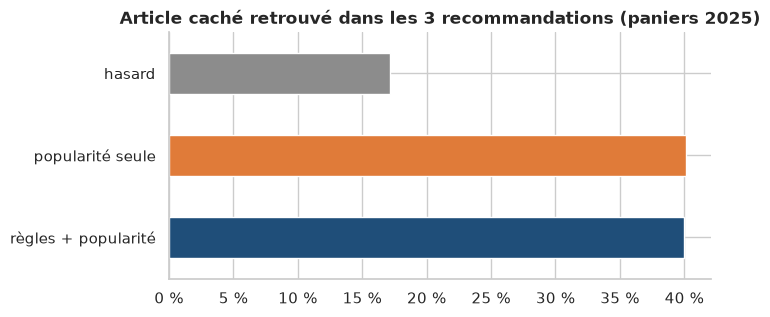

  ✔ ana.dm03_evaluation_recommandation                3 lignes


,taux de réussite (top 3),paniers évalués
règles + popularité,0.400,10650
popularité seule,0.401,10650
hasard,0.172,10650


In [10]:
rng = np.random.default_rng(42)
evalues = test_cmd[test_cmd["sous_categories"].apply(len) >= 2]["sous_categories"]
toutes_sc = populaires["sous-catégorie"]
succes = {"règles + popularité": 0, "popularité seule": 0, "hasard": 0}
for articles in evalues:
    articles = list(articles)
    cache = articles.pop(rng.integers(len(articles)))
    reco = features.recommander(articles, regles_sc, toutes_sc, n=3)["article"].tolist()
    pop = [a for a in toutes_sc if a not in articles][:3]
    hasard = list(rng.choice([a for a in toutes_sc if a not in articles], 3, replace=False))
    succes["règles + popularité"] += cache in reco
    succes["popularité seule"] += cache in pop
    succes["hasard"] += cache in hasard
evaluation = pd.DataFrame({"taux de réussite (top 3)": {k: v / len(evalues) for k, v in succes.items()}})
evaluation["paniers évalués"] = len(evalues)

fig, ax = plt.subplots(figsize=(7, 3.2))
evaluation["taux de réussite (top 3)"].plot.barh(ax=ax, color=[cfg.BLEU, cfg.ORANGE, cfg.GRIS])
ax.set_title("Article caché retrouvé dans les 3 recommandations (paniers 2025)"); cfg.format_pourcent(ax, "x")
montrer("DM03_4_evaluation_reco")
cfg.exporter_table(evaluation, "DM03_evaluation_recommandation")
evaluation

> **Lecture.** Sur **10 650 paniers de 2025**, l'article caché est retrouvé dans les 3 recommandations dans **40 %** des cas, que l'on utilise les règles ou la seule popularité, contre 17 % au hasard. Les règles **n'améliorent pas** la recommandation : toute la performance vient de la popularité (2,3 fois mieux que le hasard).

## 8. Synthèse

> **Lecture.** Conclusion honnête : il n'y a **pas d'affinité forte entre produits** dans les paniers TuniShop. Les règles stables (30 au niveau catégorie, 4 au niveau sous-catégorie) décrivent l'effet « gros panier » ; la recommandation la plus efficace est aujourd'hui la **popularité**. Les règles validées et les articles populaires sont enregistrés (`06_Exports/Modeles/regles_association.parquet`, `articles_populaires.json`) avec la fonction `features.recommander()`, réutilisables tels quels. **Piste pour le ML :** personnaliser la recommandation avec l'historique du client (catégories déjà achetées, segment) plutôt qu'avec le contenu du panier.

In [11]:
chargement.fermer_connexion()

Connexion fermée.
